# Machine-Learning In-Class Exercise - Wine Quality Prediction

**Developer:** Brandon Perez

**Course:** Artificial Intelligence Applications

## Program Requirements
1. Get  
2. Clean (if needed)  
3. Prepare  
4. Analyze  
5. Display/Visualize  
6. Identify correlations  
7. Create classifications (i.e., "good" or "bad")  
8. Make predictions (i.e., "quality" score)

**Note:** Review Assignments 2-4, Project 1, the course textbook, as well as online resources!


In [1]:
# 1. import necessary modules
import sys
import os
import pandas as pd

# for analyzing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

# for plots
import matplotlib.pyplot as plt
import seaborn as sns

print(sys.version)  # print python version
print(os.environ['CONDA_DEFAULT_ENV'])  # print conda environment

3.9.23 | packaged by conda-forge | (main, Jun  4 2025, 18:02:02) 
[Clang 18.1.8 ]
testenv


In [2]:
# 2. get wine quality data: consult: http://www.vinhoverde.pt/en/ or reference [Cortez et al., 2009]
# info: https://archive.ics.uci.edu/dataset/186/wine+quality
wine_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"

In [3]:
# 3. read csv file into DataFrame
df = pd.read_csv(wine_url, sep=';')

# Display Dataframe Characteristics

In [4]:
# 4. print number of rows and columns
print(df.shape)

(1599, 12)


In [9]:
# 5. Use Pandas DataFrame info() Method:
# Prints:
# 1. number of columns
# 2. column labels
# 3. data types
# 4. index labels
# 5. memory usage
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [10]:
# 6. display DataFrame metrics
df.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000,1599.000000
mean,8.319637,0.527821,0.270976,2.538806,0.087467,15.874922,46.467792,0.996747,3.311113,0.658149,10.422983,5.636023
std,1.741096,0.179060,0.194801,1.409928,0.047065,10.460157,32.895324,0.001887,0.154386,0.169507,1.065668,0.807569
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996750,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.420000,2.600000,0.090000,21.000000,62.000000,0.997835,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


In [11]:
# 7. print DataFrame attributes: index, columns, size, and shape
print("Index:", df.index)
print("Columns:", df.columns)
print("Shape:", df.shape)
print("Size (rows X cols):", df.size)

Index: RangeIndex(start=0, stop=1599, step=1)
Columns: Index(['fixed acidity', 'volatile acidity', 'citric acid', 'residual sugar',
       'chlorides', 'free sulfur dioxide', 'total sulfur dioxide', 'density',
       'pH', 'sulphates', 'alcohol', 'quality'],
      dtype='object')
Shape: (1599, 12)
Size (rows X cols): 19188


In [12]:
# 8. Display first and last five rows with one command!
pd.concat([df.head(), df.tail()])

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5
1598,6.0,0.310,0.47,3.6,0.067,18.0,42.0,0.99549,3.39,0.66,11.0,6


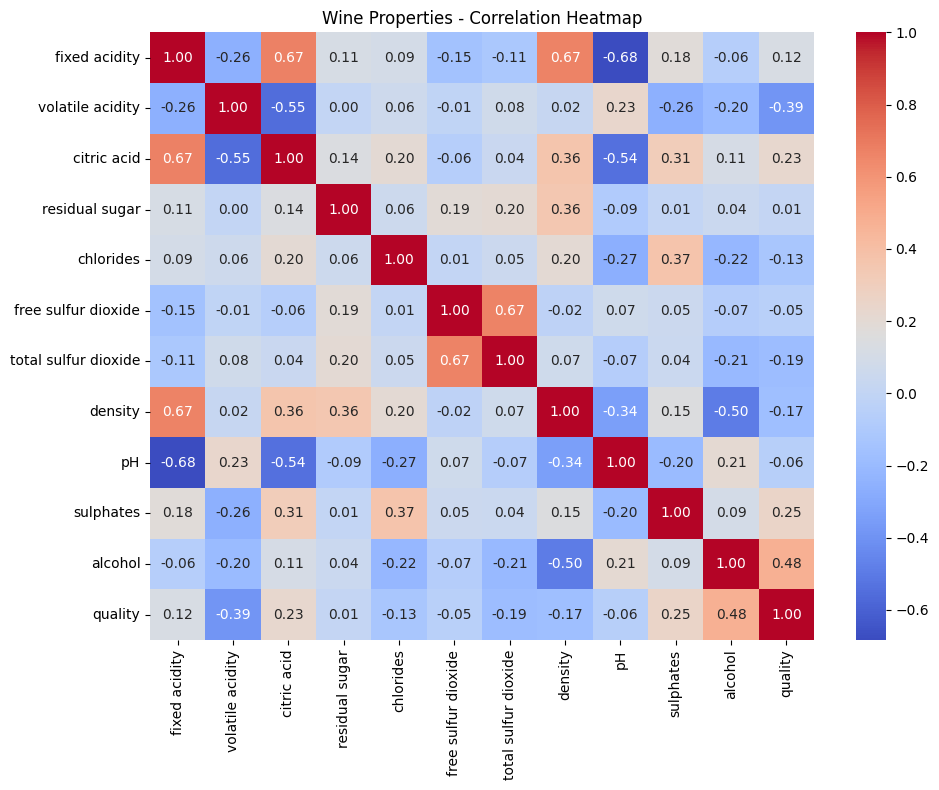

In [13]:
# 9. display correlation metrics
# Note:
# a) use correlations object and includes strong positive correlation and dark blue functions strong negative correlation
corr = df.corr(numeric_only=True)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Wine Properties - Correlation Heatmap")
plt.tight_layout()
plt.show()

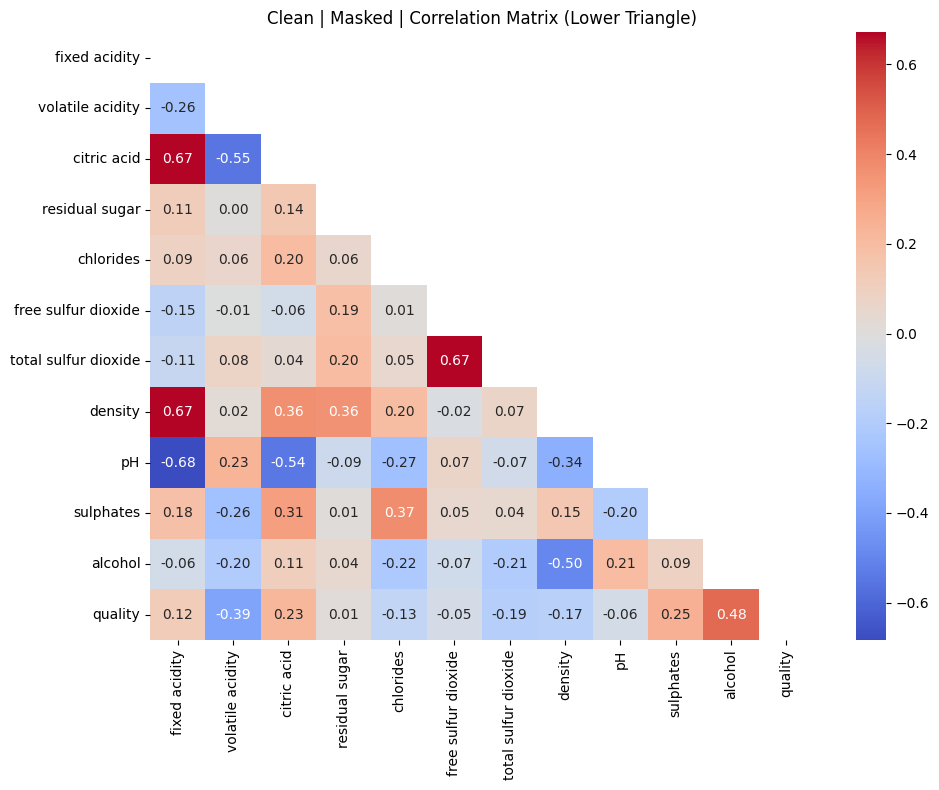

In [14]:
# 10. Masked ("triangular") Matrix; note heatmap cleaner (only asks us to hide top-right triangle)
# Note: lower triangular to simplify graph, comparison of A with B is same as B with A, top half is redundant
import numpy as np

mask = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Clean | Masked | Correlation Matrix (Lower Triangle)")
plt.tight_layout()
plt.show()

## Why is "X" uppercase and "y" lowercase?

**Answer:**

- **Features (IV):** represents matrix (2D array). Generally, multiple features, and treated as mathematical **matrix**, traditionally denoted by uppercase letter.
- **Target (DV):** represents vector (1D array). Typically only one output value per sample, treated as column **vector**, traditionally denoted by lowercase letter.

### X (Features):
- Usually 2D array or DataFrame (rows = samples, columns = features)
- Can contain numbers, categories, text, images, etc.
- In supervised learning, model learns patterns from X to predict y

### y (Target):
- Usually 1D array or Series
- For regression -> continuous value (e.g., price, temperature, salary)
- For classification -> discrete class/label (e.g., spam/not spam, cat/dog, 0/1)


In [15]:
# 11. create new col indicating "is_good" based upon existing "quality" col
# Note: use >=7 in "quality" col to determine good wine (creates NEW binary df col "is_good")

df["is_good"] = (df["quality"] >= 7).astype(int)

# show new df with binary col (is_good) displays 0 or 1!
df

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_good
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,0
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,0
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,0
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,0
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,0
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2,5,0


In [16]:
# 12. create and display independent variable (X) by returning NEW dataframe that removes 'quality' and 'is_good' cols from df

# display X
X = df.drop(columns=["quality", "is_good"])
X

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4
...,...,...,...,...,...,...,...,...,...,...,...
1594,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5
1595,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2
1596,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0
1597,5.9,0.645,0.12,2.0,0.075,32.0,44.0,0.99547,3.57,0.71,10.2


In [17]:
# 13. create and display dependent variable (y) by returning data from source "quality" and 'is_good' cols from df
y = df["is_good"]
y

0       0
1       0
2       0
3       0
4       0
       ..
1594    0
1595    0
1596    0
1597    0
1598    0
Name: is_good, Length: 1599, dtype: int64

# Prepare Model

In [18]:
# 14. split data (80% train / 20% test)

# returns four results (all Pandas "Series" data type):
# X_train and X_test: contain independent variables
# y_train and y_test: contain binary values (0 or 1) from is_good column
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

In [19]:
# 15. Scale Features (IV): also known as Z-score normalization
# Note: Feature Scaling: Since chemical measurements vary in scale (e.g., pH is small, while sulfur dioxide is large),
# use StandardScaler from scikit-learn to normalize data: use fit_transform() and transform()

# Why? Prevents features with larger scales from dominating those with smaller scales
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [20]:
# 16. display new X train scaled feature values
X_train_scaled

array([[ 1.07100074, -0.59949467,  1.53130838, ..., -1.77013426,
        -0.17977295, -0.78194777],
       [-0.1970216 , -1.94966075,  0.49744889, ..., -2.74878115,
        -1.31155079,  2.09526879],
       [-0.65812063,  0.44125834, -1.31180522, ...,  0.97007704,
        -0.7754455 ,  1.25994785],
       ...,
       [ 0.78281385, -0.59949467,  0.96268566, ..., -0.26954236,
         0.47546685,  1.72401504],
       [-1.11921966,  1.51013982, -1.41519117, ...,  1.16580642,
        -0.83501275,  1.07432098],
       [-1.58031869,  2.18522285, -1.41519117, ...,  2.40542581,
         0.4158996 ,  0.8886941 ]])

In [21]:
# 17. display new X test scaled feature values
X_test_scaled

array([[ 1.1862755 , -0.65575159,  1.42792243, ..., -1.05245987,
         1.36897567, -0.50350745],
       [-0.08174684,  0.24435912, -0.07117383, ..., -0.07381298,
        -1.37111804, -0.31788058],
       [-0.88867014,  0.80692832, -1.41519117, ...,  0.57861828,
         0.47546685, -0.68913433],
       ...,
       [-0.88867014,  0.63815756, -0.89826142, ...,  0.18715952,
        -0.83501275, -0.22506714],
       [-0.94630752,  1.3132406 , -1.31180522, ...,  1.55726517,
        -0.17977295, -0.45710074],
       [ 2.2813857 , -0.14943932,  1.11776459, ..., -0.79148737,
        -1.31155079, -0.78194777]])

# Train and Assess

In [22]:
# 18. Train and Evaluate/Assess:
# a. create model, fit model, create variable "predictions"

model = RandomForestClassifier(random_state=42)
model.fit(X_train_scaled, y_train)

predictions = model.predict(X_test_scaled)

# Weighted Average:
print(f"Accuracy: {accuracy_score(y_test, predictions):.2%}")
print(classification_report(y_test, predictions))

Accuracy: 93.75%
              precision    recall  f1-score   support

           0       0.94      0.99      0.96       277
           1       0.93      0.58      0.71        43

    accuracy                           0.94       320
   macro avg       0.93      0.79      0.84       320
weighted avg       0.94      0.94      0.93       320



# Plot Data

In [23]:
# 19. Extract feature_importances (chemical properties that most significantly impact wine's quality rating)

# create DataFrame for easier plotting
feature_importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

# display DF feature_importance
feature_importance

,Feature,Importance
10,alcohol,0.173564
9,sulphates,0.111345
7,density,0.102920
1,volatile acidity,0.102421
2,citric acid,0.093135
6,total sulfur dioxide,0.078180
0,fixed acidity,0.076296
3,residual sugar,0.069652
4,chlorides,0.068110
8,pH,0.065280


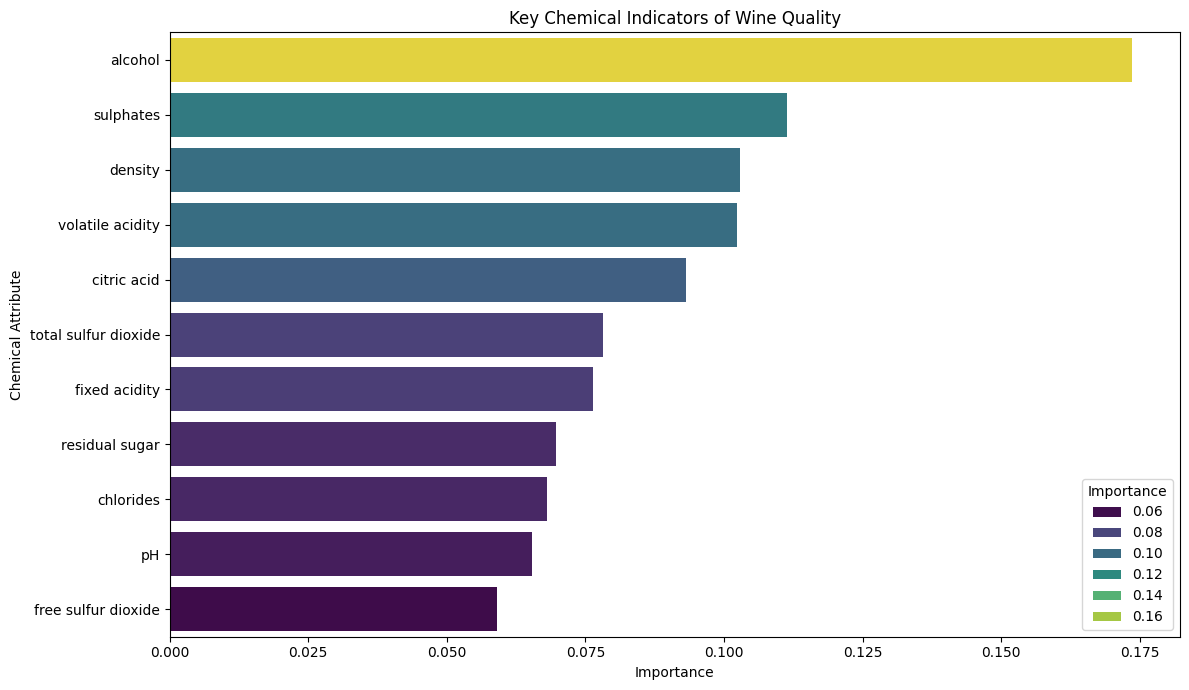

In [24]:
# 20. plot feature importances

# color bars based on "Importance"

plt.figure(figsize=(12, 7))
sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature",
    hue="Importance",
    dodge=False,
    palette="viridis"
)
plt.title("Key Chemical Indicators of Wine Quality")
plt.ylabel("Chemical Attribute")
plt.xlabel("Importance")
plt.legend(title="Importance")
plt.tight_layout()
plt.show()

# Note:
# Based on feature importance, Alcohol and Sulphates are generally strongest indicators of higher wine quality in this dataset!